# Phase-1 Cell 1 — Basic setup + path inspection

In [1]:
import os
from pathlib import Path

INPUT_ROOT = Path("/kaggle/input")
WORK_ROOT  = Path("/kaggle/working")

print("INPUT_ROOT:", INPUT_ROOT)
print("WORK_ROOT :", WORK_ROOT)

if not INPUT_ROOT.exists():
    raise RuntimeError("expected /kaggle/input to exist")

print("\n folders under /kaggle/input:\n")
for p in sorted(INPUT_ROOT.iterdir()):
    if p.is_dir():
        print(" -", p.name)


INPUT_ROOT: /kaggle/input
WORK_ROOT : /kaggle/working

 folders under /kaggle/input:

 - datasets
 - structural-defects-network-concrete-crack-images


# Phase-1 Cell 2 — Robust dataset locator

In [2]:
from typing import Optional, List, Tuple

IMG_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}

def count_images(folder: Path) -> int:
    return sum(1 for p in folder.rglob("*") if p.suffix.lower() in IMG_EXTS)

def find_sdnet_root(root: Path) -> Optional[Path]:

    for d in root.rglob("*"):
        if not d.is_dir():
            continue
        if (d / "Walls").is_dir() and (d / "Decks").is_dir() and (d / "Pavements").is_dir():
            return d
    return None

def find_segmentation_roots(root: Path) -> List[Path]:

    candidates = []
    for d in root.rglob("*"):
        if not d.is_dir():
            continue
        try:
            kids = {c.name.lower(): c for c in d.iterdir() if c.is_dir()}
        except Exception:
            continue
        if "images" in kids and "masks" in kids:
            candidates.append(d)
    return candidates

SDNET_DIR = find_sdnet_root(INPUT_ROOT)
SEG_ROOTS = find_segmentation_roots(INPUT_ROOT)

print("Detected SDNET_DIR:", SDNET_DIR)
print("\nDetected segmentation roots (images+masks):")
for r in SEG_ROOTS[:20]:
    print(" -", r)
if len(SEG_ROOTS) > 20:
    print(" ... (truncated)")


Detected SDNET_DIR: /kaggle/input/structural-defects-network-concrete-crack-images

Detected segmentation roots (images+masks):
 - /kaggle/input/datasets/lakshaymiddha/crack-segmentation-dataset/crack_segmentation_dataset
 - /kaggle/input/datasets/lakshaymiddha/crack-segmentation-dataset/crack_segmentation_dataset/test
 - /kaggle/input/datasets/lakshaymiddha/crack-segmentation-dataset/crack_segmentation_dataset/train


# Phase-1 Cell 3 — Choosing the best segmentation root automatically

In [3]:
import numpy as np

if SDNET_DIR is None:
    raise RuntimeError("Could not locate SDNET root")

if len(SEG_ROOTS) == 0:
    raise RuntimeError("Could not locate any folder that contains both 'images' and 'masks' subfolders.")

def best_seg_root(seg_roots: List[Path]) -> Tuple[Path, int, int]:
    scored = []
    for r in seg_roots:
        img_dir = r / "images"
        msk_dir = r / "masks"
        n_img = count_images(img_dir)
        n_msk = count_images(msk_dir)
        scored.append((r, n_img, n_msk))
    scored.sort(key=lambda x: min(x[1], x[2]), reverse=True)
    return scored[0]

SEG_DIR, N_IMG, N_MSK = best_seg_root(SEG_ROOTS)

print("Selected SEG_DIR:", SEG_DIR)
print("Images:", N_IMG)
print("Masks :", N_MSK)


# SEG_DIR = Path("/kaggle/input/datasets/lakshaymiddha/crack-segmentation-dataset/crack_segmentation_dataset")


Selected SEG_DIR: /kaggle/input/datasets/lakshaymiddha/crack-segmentation-dataset/crack_segmentation_dataset
Images: 11298
Masks : 11298


# Phase-1 Cell 4 — Define SDNET walls paths

In [4]:
SDNET_WALLS_CRACKED     = SDNET_DIR / "Walls" / "Cracked"
SDNET_WALLS_NONCRACKED  = SDNET_DIR / "Walls" / "Non-cracked"

print("SDNET_WALLS_CRACKED    :", SDNET_WALLS_CRACKED, "exists:", SDNET_WALLS_CRACKED.exists())
print("SDNET_WALLS_NONCRACKED :", SDNET_WALLS_NONCRACKED, "exists:", SDNET_WALLS_NONCRACKED.exists())

if not SDNET_WALLS_CRACKED.exists() or not SDNET_WALLS_NONCRACKED.exists():
    raise RuntimeError("SDNET Walls folders not found. Expand SDNET_DIR tree to confirm structure.")


SDNET_WALLS_CRACKED    : /kaggle/input/structural-defects-network-concrete-crack-images/Walls/Cracked exists: True
SDNET_WALLS_NONCRACKED : /kaggle/input/structural-defects-network-concrete-crack-images/Walls/Non-cracked exists: True


# Phase-1 Cell 5 — Verify segmentation pairing by filename stem

In [5]:
from PIL import Image
import random

IMG_DIR = SEG_DIR / "images"
MSK_DIR = SEG_DIR / "masks"

img_files = sorted([p for p in IMG_DIR.rglob("*") if p.suffix.lower() in IMG_EXTS])
msk_files = sorted([p for p in MSK_DIR.rglob("*") if p.suffix.lower() in IMG_EXTS])

print("SEG images:", len(img_files))
print("SEG masks :", len(msk_files))

img_stems = {p.stem for p in img_files}
msk_stems = {p.stem for p in msk_files}

paired = sorted(list(img_stems & msk_stems))
print("Paired stems:", len(paired))

if len(paired) == 0:
    raise RuntimeError("No paired image/mask stems found. Dataset may use different naming.")


SEG images: 11298
SEG masks : 11298
Paired stems: 11298


# Phase-1 Cell 6 — Visual sanity check 

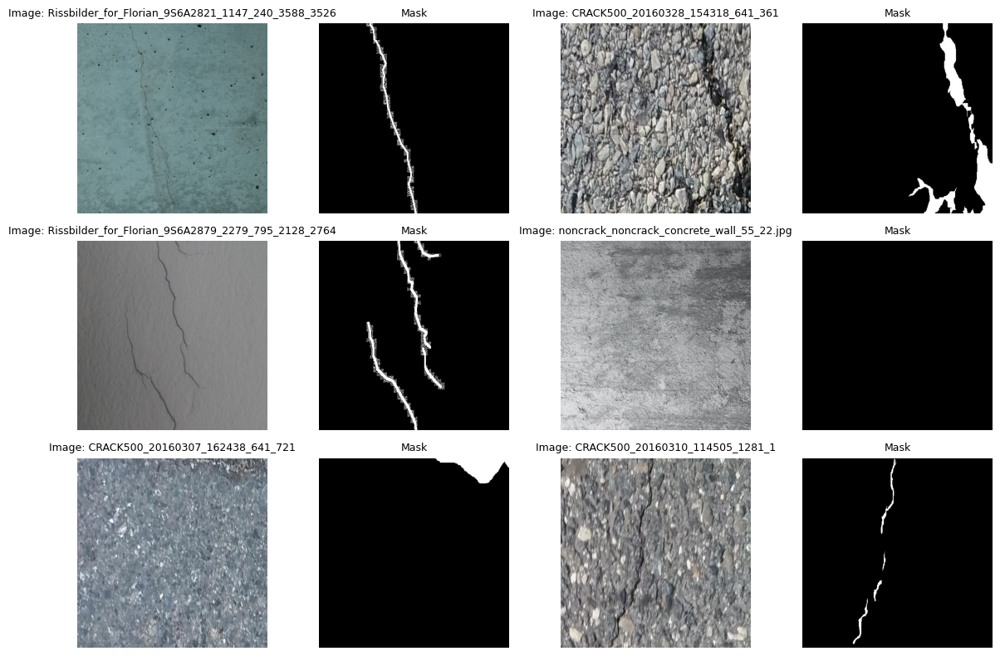

In [6]:
import matplotlib.pyplot as plt
import numpy as np

random.seed(7)

sample = random.sample(paired, k=min(6, len(paired)))

def load_rgb(path: Path):
    return np.array(Image.open(path).convert("RGB"))

def load_mask(path: Path):
    m = Image.open(path)
    return np.array(m)

plt.figure(figsize=(12, 8))

for i, stem in enumerate(sample):
    img_path = next(p for p in img_files if p.stem == stem)
    msk_path = next(p for p in msk_files if p.stem == stem)

    img = load_rgb(img_path)
    msk = load_mask(msk_path)

    ax1 = plt.subplot(3, 4, 2*i + 1)
    ax1.imshow(img)
    ax1.set_title(f"Image: {stem}", fontsize=9)
    ax1.axis("off")

    ax2 = plt.subplot(3, 4, 2*i + 2)
    ax2.imshow(msk, cmap="gray")
    ax2.set_title("Mask", fontsize=9)
    ax2.axis("off")

plt.tight_layout()
plt.show()


# Phase-1 Cell 7 — Quick SDNET walls counts (cracked vs non-cracked)

In [7]:
def list_images(folder: Path) -> List[Path]:
    return [p for p in folder.rglob("*") if p.suffix.lower() in IMG_EXTS]

walls_cr = list_images(SDNET_WALLS_CRACKED)
walls_nc = list_images(SDNET_WALLS_NONCRACKED)

print("SDNET Walls cracked    :", len(walls_cr))
print("SDNET Walls non-cracked:", len(walls_nc))


SDNET Walls cracked    : 3851
SDNET Walls non-cracked: 14287


# Phase-2 Cell 1 — Imports, config, and safe path re-attach

In [8]:
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from PIL import Image

IMG_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}

SEED = 7
random.seed(SEED)
np.random.seed(SEED)

INPUT_ROOT = Path("/kaggle/input")


SDNET_DIR = globals().get("SDNET_DIR", Path("/kaggle/input/structural-defects-network-concrete-crack-images"))
SEG_DIR   = globals().get("SEG_DIR",   Path("/kaggle/input/datasets/lakshaymiddha/crack-segmentation-dataset/crack_segmentation_dataset"))

SDNET_WALLS_CRACKED    = SDNET_DIR / "Walls" / "Cracked"
SDNET_WALLS_NONCRACKED = SDNET_DIR / "Walls" / "Non-cracked"

IMG_DIR = SEG_DIR / "images"
MSK_DIR = SEG_DIR / "masks"

print("SDNET_DIR:", SDNET_DIR)
print("SEG_DIR  :", SEG_DIR)
print("Walls cracked exists    :", SDNET_WALLS_CRACKED.exists())
print("Walls non-cracked exists:", SDNET_WALLS_NONCRACKED.exists())
print("Seg images exists:", IMG_DIR.exists())
print("Seg masks  exists:", MSK_DIR.exists())


SDNET_DIR: /kaggle/input/structural-defects-network-concrete-crack-images
SEG_DIR  : /kaggle/input/datasets/lakshaymiddha/crack-segmentation-dataset/crack_segmentation_dataset
Walls cracked exists    : True
Walls non-cracked exists: True
Seg images exists: True
Seg masks  exists: True


# Phase-2 Cell 1A — Output folders + figure saving utility

In [9]:
from pathlib import Path
import matplotlib.pyplot as plt

WORK_ROOT = Path("/kaggle/working")
FIG_DIR   = WORK_ROOT / "output" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

def save_fig(name: str, dpi: int = 350):
    out_path = FIG_DIR / f"{name}.png"
    plt.savefig(out_path, dpi=dpi, bbox_inches="tight", pad_inches=0.08, facecolor="white")
    print("Saved:", out_path)


# Phase-2 Cell 2 — Build SDNET Walls dataframe (paths + labels)

In [10]:
def list_images(folder: Path):
    return [p for p in folder.rglob("*") if p.suffix.lower() in IMG_EXTS]

walls_cr = list_images(SDNET_WALLS_CRACKED)
walls_nc = list_images(SDNET_WALLS_NONCRACKED)

df_sdnet_walls = pd.DataFrame({
    "path": walls_cr + walls_nc,
    "label": (["Cracked"] * len(walls_cr)) + (["Non-cracked"] * len(walls_nc))
})

print("SDNET Walls samples:", len(df_sdnet_walls))
df_sdnet_walls["label"].value_counts()


SDNET Walls samples: 18138


label
Non-cracked    14287
Cracked         3851
Name: count, dtype: int64

# Phase-2 Cell 3 — Class Distribution Bar Chart (SDNET Walls)

Saved: /kaggle/working/output/figures/phase2_cell3_sdnet_walls_class_distribution.png


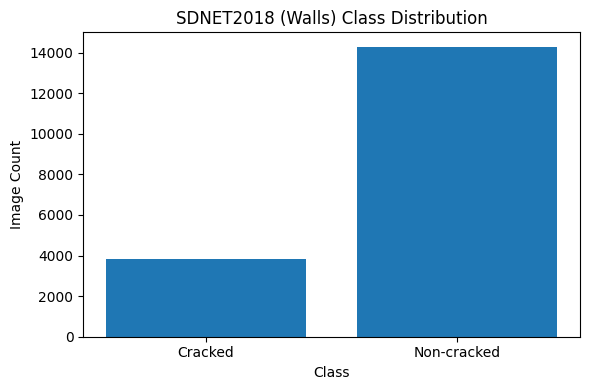

In [11]:
counts = df_sdnet_walls["label"].value_counts().sort_index()

plt.figure(figsize=(6,4))
plt.bar(counts.index, counts.values)
plt.title("SDNET2018 (Walls) Class Distribution")
plt.xlabel("Class")
plt.ylabel("Image Count")
plt.xticks(rotation=0)
plt.tight_layout()
save_fig("phase2_cell3_sdnet_walls_class_distribution")


plt.show()



# Phase-2 Cell 4 — Sample Montage with Grid Labels (SDNET Walls)

Saved: /kaggle/working/output/figures/phase2_cell4_sdnet_walls_montage.png


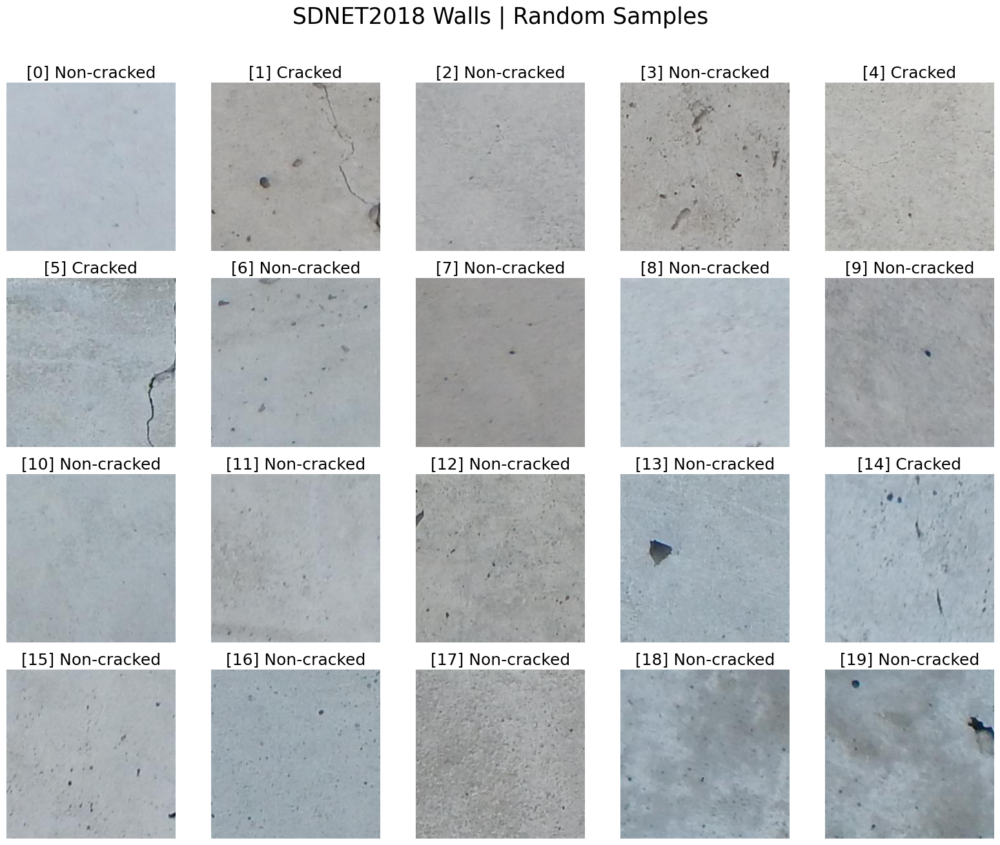

In [12]:
def load_rgb(path: Path):
    return np.array(Image.open(path).convert("RGB"))

def montage_sdnet(df, n=16, ncols=4, title="SDNET Walls Montage"):
    n = min(n, len(df))
    sample_df = df.sample(n=n, random_state=SEED).reset_index(drop=True)

    nrows = int(np.ceil(n / ncols))
    plt.figure(figsize=(3.2*ncols, 3.2*nrows))
    plt.suptitle(title, y=1.02, fontsize=25)

    for i in range(n):
        p = sample_df.loc[i, "path"]
        y = sample_df.loc[i, "label"]

        img = load_rgb(p)

        ax = plt.subplot(nrows, ncols, i+1)
        ax.imshow(img)
        ax.axis("off")
        ax.set_title(f"[{i}] {y}", fontsize=18)

    plt.tight_layout()
    save_fig("phase2_cell4_sdnet_walls_montage", dpi=300)


    plt.show()

montage_sdnet(df_sdnet_walls, n=20, ncols=5, title="SDNET2018 Walls | Random Samples")


# Phase-2 Cell 5 — Sample Montage with Grid Labels (Segmentation dataset: image + mask overlay)

Segmentation pairs: 11298
Saved: /kaggle/working/output/figures/phase2_cell5_segmentation_overlay_montage.png


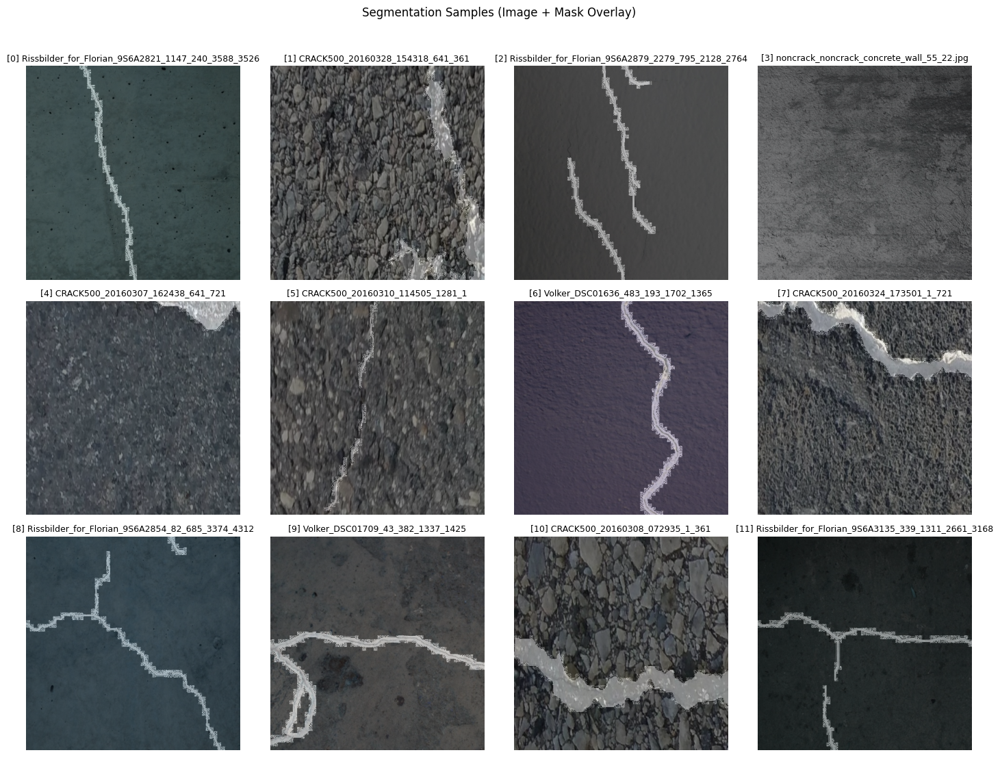

In [13]:
def list_seg_pairs(img_dir: Path, msk_dir: Path):
    imgs = sorted([p for p in img_dir.rglob("*") if p.suffix.lower() in IMG_EXTS])
    msks = sorted([p for p in msk_dir.rglob("*") if p.suffix.lower() in IMG_EXTS])

    img_map = {p.stem: p for p in imgs}
    msk_map = {p.stem: p for p in msks}
    stems = sorted(list(set(img_map.keys()) & set(msk_map.keys())))
    pairs = [(img_map[s], msk_map[s]) for s in stems]
    return pairs

pairs = list_seg_pairs(IMG_DIR, MSK_DIR)
print("Segmentation pairs:", len(pairs))

def montage_seg(pairs, n=8, ncols=4, alpha=0.45, title="Segmentation Samples (Image + Mask Overlay)"):
    n = min(n, len(pairs))
    chosen = random.sample(pairs, k=n)

    nrows = int(np.ceil(n / ncols))
    plt.figure(figsize=(3.6*ncols, 3.6*nrows))
    plt.suptitle(title, y=1.02, fontsize=12)

    for i, (ip, mp) in enumerate(chosen):
        img = np.array(Image.open(ip).convert("RGB"))
        msk = np.array(Image.open(mp))

        if msk.ndim == 3:
            msk = msk[..., 0]
        msk = (msk > 0).astype(np.uint8)

        ax = plt.subplot(nrows, ncols, i+1)
        ax.imshow(img)
        ax.imshow(msk, alpha=alpha, cmap="gray")
        ax.axis("off")
        ax.set_title(f"[{i}] {ip.stem}", fontsize=9)

    plt.tight_layout()
    save_fig("phase2_cell5_segmentation_overlay_montage", dpi=300)
    plt.show()

montage_seg(pairs, n=12, ncols=4)


# Phase-2 Cell 6 — Color Channel Intensity Histograms (SDNET vs Seg dataset)

Saved: /kaggle/working/output/figures/phase2_cell6_rgb_histograms_sdnet_vs_seg.png


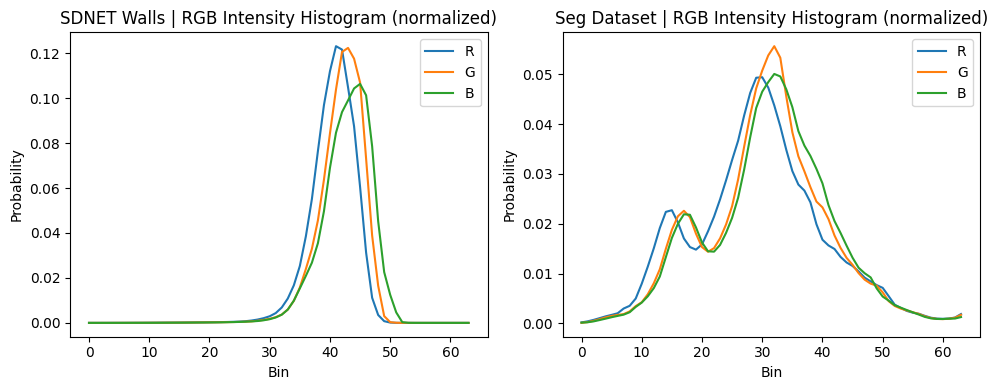

In [14]:
def sample_paths(paths, k=300):
    k = min(k, len(paths))
    return random.sample(paths, k=k)

def channel_hist(paths, bins=64, resize_to=256):
    hist = np.zeros((3, bins), dtype=np.float64)

    for p in paths:
        img = Image.open(p).convert("RGB")
        if resize_to is not None:
            img = img.resize((resize_to, resize_to))
        arr = np.asarray(img).astype(np.uint8)

        for c in range(3):
            h, _ = np.histogram(arr[..., c].ravel(), bins=bins, range=(0,255))
            hist[c] += h

    hist = hist / hist.sum(axis=1, keepdims=True)
    return hist

sdnet_sample = sample_paths(df_sdnet_walls["path"].tolist(), k=400)
seg_sample   = sample_paths([ip for ip, mp in pairs], k=400)

hist_sdnet = channel_hist(sdnet_sample, bins=64, resize_to=256)
hist_seg   = channel_hist(seg_sample,   bins=64, resize_to=256)

x = np.arange(64)

plt.figure(figsize=(10,4))
plt.subplot(1,2,1)
plt.plot(x, hist_sdnet[0], label="R")
plt.plot(x, hist_sdnet[1], label="G")
plt.plot(x, hist_sdnet[2], label="B")
plt.title("SDNET Walls | RGB Intensity Histogram (normalized)")
plt.xlabel("Bin")
plt.ylabel("Probability")
plt.legend()

plt.subplot(1,2,2)
plt.plot(x, hist_seg[0], label="R")
plt.plot(x, hist_seg[1], label="G")
plt.plot(x, hist_seg[2], label="B")
plt.title("Seg Dataset | RGB Intensity Histogram (normalized)")
plt.xlabel("Bin")
plt.ylabel("Probability")
plt.legend()

plt.tight_layout()
save_fig("phase2_cell6_rgb_histograms_sdnet_vs_seg", dpi=350)
plt.show()


# Phase-2 Cell 7 — Augmentation Preview (image + mask, segmentation-safe)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 137.0/137.0 kB 7.8 MB/s eta 0:00:00
Saved: /kaggle/working/output/figures/phase2_cell7_augmentation_preview.png


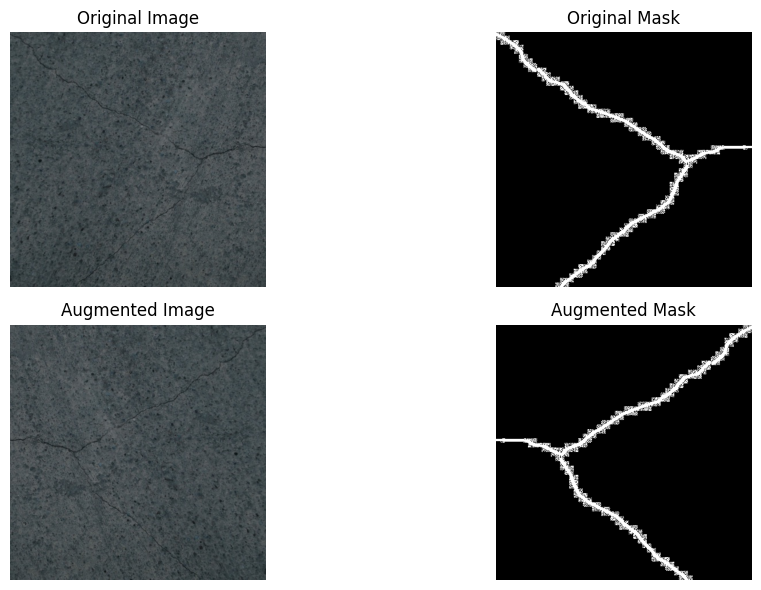

In [15]:
!pip -q install albumentations==1.4.3

import albumentations as A

aug = A.Compose(
    [
        A.HorizontalFlip(p=0.5),
        A.VerticalFlip(p=0.2),
        A.Rotate(limit=20, border_mode=0, p=0.7),
        A.RandomBrightnessContrast(p=0.7),
        A.GaussNoise(p=0.3),
        A.Blur(blur_limit=3, p=0.2),
    ],
    additional_targets={"mask": "mask"}
)

(ip, mp) = random.choice(pairs)

img = np.array(Image.open(ip).convert("RGB"))
msk = np.array(Image.open(mp))
if msk.ndim == 3:
    msk = msk[..., 0]
msk = (msk > 0).astype(np.uint8) * 255

augmented = aug(image=img, mask=msk)
img_a = augmented["image"]
msk_a = augmented["mask"]

plt.figure(figsize=(12,6))

plt.subplot(2,2,1)
plt.imshow(img)
plt.title("Original Image")
plt.axis("off")

plt.subplot(2,2,2)
plt.imshow(msk, cmap="gray")
plt.title("Original Mask")
plt.axis("off")

plt.subplot(2,2,3)
plt.imshow(img_a)
plt.title("Augmented Image")
plt.axis("off")

plt.subplot(2,2,4)
plt.imshow(msk_a, cmap="gray")
plt.title("Augmented Mask")
plt.axis("off")

plt.tight_layout()
save_fig("phase2_cell7_augmentation_preview", dpi=350)
plt.show()


# Phase-2 Cell 8 — Image Aspect Ratio Scatter Plot (SDNET walls vs Seg dataset)

In [16]:
import os
from pathlib import Path
import pandas as pd
from PIL import Image

INPUT_ROOT = Path("/kaggle/input")

def find_first_dir_contains(pattern: str):
    for p in INPUT_ROOT.rglob("*"):
        if p.is_dir() and pattern.lower() in p.name.lower():
            return p
    return None

def safe_image_size(fp: Path):
    try:
        with Image.open(fp) as im:
            w, h = im.size
        return w, h
    except Exception:
        return None

if "df_ar" not in globals():
    # SDNET (Walls)
    sdnet_root = find_first_dir_contains("structural-defects-network")
    if sdnet_root is None:
        sdnet_root = find_first_dir_contains("sdnet")
    if sdnet_root is None:
        raise RuntimeError("Could not find SDNET folder under /kaggle/input")

    sdnet_walls = sdnet_root / "Walls"
    sdnet_imgs = list(sdnet_walls.rglob("*.jpg")) + list(sdnet_walls.rglob("*.png"))

    # Crack Segmentation dataset (images)
    seg_root = find_first_dir_contains("crack_segmentation_dataset")
    if seg_root is None:
        seg_root = find_first_dir_contains("crack-segmentation")
    if seg_root is None:
        raise RuntimeError("Could not find crack segmentation folder under /kaggle/input")

    seg_images_dir = seg_root / "images"
    if not seg_images_dir.exists():
        # Some Kaggle datasets nest this folder deeper
        cand = list(seg_root.rglob("images"))
        if len(cand) == 0:
            raise RuntimeError("Could not locate an 'images' folder inside the segmentation dataset.")
        seg_images_dir = cand[0]

    seg_imgs = list(seg_images_dir.rglob("*.jpg")) + list(seg_images_dir.rglob("*.png"))

    rows = []

    for fp in sdnet_imgs:
        s = safe_image_size(fp)
        if s is None:
            continue
        w, h = s
        rows.append({"dataset": "SDNET_Walls", "W": w, "H": h, "aspect_ratio": w / max(h, 1)})

    for fp in seg_imgs:
        s = safe_image_size(fp)
        if s is None:
            continue
        w, h = s
        rows.append({"dataset": "Segmentation", "W": w, "H": h, "aspect_ratio": w / max(h, 1)})

    df_ar = pd.DataFrame(rows)
    print("Built df_ar:", df_ar.shape)
    print(df_ar.groupby("dataset")[["W","H","aspect_ratio"]].describe().round(3))

else:
    print("df_ar already exists:", df_ar.shape)


Built df_ar: (29436, 4)
                    W                                                       H  \
                count   mean  std    min    25%    50%    75%    max    count   
dataset                                                                         
SDNET_Walls   18138.0  256.0  0.0  256.0  256.0  256.0  256.0  256.0  18138.0   
Segmentation  11298.0  448.0  0.0  448.0  448.0  448.0  448.0  448.0  11298.0   

                     ...               aspect_ratio                           \
               mean  ...    75%    max        count mean  std  min  25%  50%   
dataset              ...                                                       
SDNET_Walls   256.0  ...  256.0  256.0      18138.0  1.0  0.0  1.0  1.0  1.0   
Segmentation  448.0  ...  448.0  448.0      11298.0  1.0  0.0  1.0  1.0  1.0   

                        
              75%  max  
dataset                 
SDNET_Walls   1.0  1.0  
Segmentation  1.0  1.0  

[2 rows x 24 columns]


Saved: /kaggle/working/output/figures/phase2_cell8a_image_size_scatter_w_vs_h.png | bytes: 148554


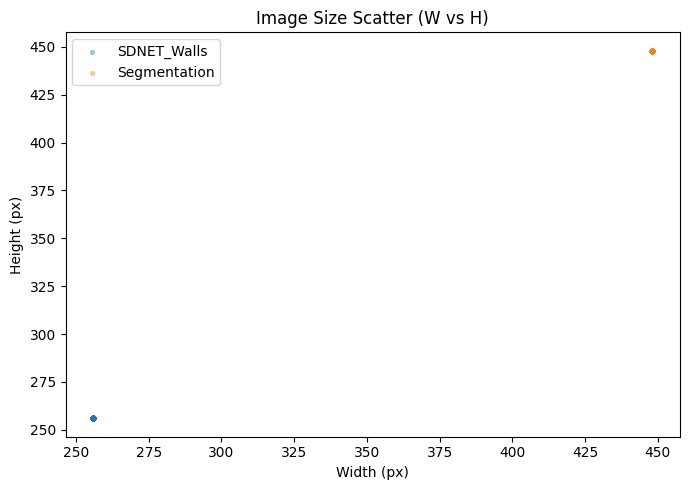

Saved: /kaggle/working/output/figures/phase2_cell8b_aspect_ratio_histogram.png | bytes: 136395


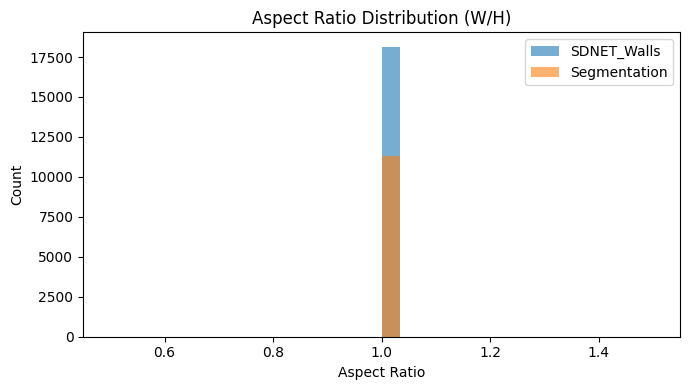


Files in: /kaggle/working/output/figures
 - phase2_cell8a_image_size_scatter_w_vs_h.png | 148554 bytes
 - phase2_cell8b_aspect_ratio_histogram.png | 136395 bytes


In [17]:
import matplotlib.pyplot as plt
from pathlib import Path
import os

WORK_ROOT = Path("/kaggle/working")
FIG_DIR   = WORK_ROOT / "output" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

def fig_save(fig, filename: str, dpi: int = 450):
    out_path = FIG_DIR / filename
    fig.savefig(out_path, dpi=dpi, bbox_inches="tight", pad_inches=0.08, facecolor="white")
    print("Saved:", out_path, "| bytes:", out_path.stat().st_size)

# ---------- Figure A: Image size scatter ----------
figA, axA = plt.subplots(figsize=(7,5))

for name, d in df_ar.groupby("dataset"):
    axA.scatter(d["W"], d["H"], s=8, alpha=0.35, label=name)

axA.set_title("Image Size Scatter (W vs H)")
axA.set_xlabel("Width (px)")
axA.set_ylabel("Height (px)")
axA.legend()
figA.tight_layout()

fig_save(figA, "phase2_cell8a_image_size_scatter_w_vs_h.png", dpi=450)
plt.show()
plt.close(figA)

# ---------- Figure B: Aspect ratio histogram ----------
figB, axB = plt.subplots(figsize=(7,4))

for name, d in df_ar.groupby("dataset"):
    axB.hist(d["aspect_ratio"], bins=30, alpha=0.6, label=name)

axB.set_title("Aspect Ratio Distribution (W/H)")
axB.set_xlabel("Aspect Ratio")
axB.set_ylabel("Count")
axB.legend()
figB.tight_layout()

fig_save(figB, "phase2_cell8b_aspect_ratio_histogram.png", dpi=450)
plt.show()
plt.close(figB)

# Quick directory listing
print("\nFiles in:", FIG_DIR)
for p in sorted(FIG_DIR.glob("phase2_cell8*.png")):
    print(" -", p.name, "|", p.stat().st_size, "bytes")


# Phase-3 Cell 1 — Install libraries

In [18]:
!pip -q uninstall -y timm segmentation-models-pytorch
!pip -q install --no-cache-dir timm==0.9.2 segmentation-models-pytorch==0.3.3 torchmetrics==1.3.2


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 68.5/68.5 kB 83.7 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.8/58.8 kB 211.9 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 141.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 106.7/106.7 kB 326.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 841.5/841.5 kB 357.6 MB/s eta 0:00:00


In [19]:
import timm
import segmentation_models_pytorch as smp
import torchmetrics

print("timm:", timm.__version__)
print("smp :", smp.__version__)
print("torchmetrics:", torchmetrics.__version__)


/usr/local/lib/python3.12/dist-packages/pydantic/_internal/_generate_schema.py:2249: UnsupportedFieldAttributeWarning: The 'repr' attribute with value False was provided to the `Field()` function, which has no effect in the context it was used. 'repr' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an `Annotated` type alias using the `type` statement was used, or if the `Field()` function was attached to a single member of a union type.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/pydantic/_internal/_generate_schema.py:2249: UnsupportedFieldAttributeWarning: The 'frozen' attribute with value True was provided to the `Field()` function, which has no effect in the context it was used. 'frozen' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an `Annotated` type alias using the `type` 

timm: 0.9.2
smp : 0.3.3
torchmetrics: 1.3.2


# Cell A — Checkpoint paths + save function

In [20]:
from pathlib import Path
import torch

WORK_ROOT = Path("/kaggle/working")
RUN_DIR   = WORK_ROOT / "output" / "runs" / "seg_v1"
CKPT_DIR  = RUN_DIR / "checkpoints"
CKPT_DIR.mkdir(parents=True, exist_ok=True)

BEST_CKPT = CKPT_DIR / "best.pt"
LAST_CKPT = CKPT_DIR / "last.pt"

def save_checkpoint(model, optimizer, scaler, epoch, best_metric, filename):
    payload = {
        "epoch": epoch,
        "best_metric": best_metric,
        "model_state": model.state_dict(),
        "opt_state": optimizer.state_dict(),
        "scaler_state": scaler.state_dict() if scaler is not None else None,
    }
    torch.save(payload, filename)
    print("Saved checkpoint:", filename)


# Cell B — Resume logic

In [21]:
import os

def load_checkpoint_if_available(model, optimizer=None, scaler=None, ckpt_path=LAST_CKPT, device="cuda"):
    if not ckpt_path.exists():
        print("No checkpoint found at:", ckpt_path)
        return 0, -1.0  # start_epoch, best_metric

    ckpt = torch.load(ckpt_path, map_location=device)
    model.load_state_dict(ckpt["model_state"])

    if optimizer is not None and "opt_state" in ckpt and ckpt["opt_state"] is not None:
        optimizer.load_state_dict(ckpt["opt_state"])

    if scaler is not None and ckpt.get("scaler_state") is not None:
        scaler.load_state_dict(ckpt["scaler_state"])

    start_epoch = int(ckpt.get("epoch", 0)) + 1
    best_metric = float(ckpt.get("best_metric", -1.0))

    print(f"Loaded checkpoint: {ckpt_path} | resume at epoch {start_epoch} | best_metric {best_metric:.4f}")
    return start_epoch, best_metric


# Phase-3 Cell-2 — Imports, reproducibility, output folders, figure saver

In [22]:
import os
import json
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from PIL import Image

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

import albumentations as A
from albumentations.pytorch import ToTensorV2

import segmentation_models_pytorch as smp
from tqdm import tqdm

SEED = 7
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("DEVICE:", DEVICE)

WORK_ROOT = Path("/kaggle/working")
FIG_DIR   = WORK_ROOT / "output" / "figures"
RUN_DIR   = WORK_ROOT / "output" / "runs" / "seg_unet_v1"
CKPT_DIR  = RUN_DIR / "checkpoints"

for d in [FIG_DIR, RUN_DIR, CKPT_DIR]:
    d.mkdir(parents=True, exist_ok=True)

def fig_save(fig, filename: str, dpi: int = 450):
    out_path = FIG_DIR / filename
    fig.savefig(out_path, dpi=dpi, bbox_inches="tight", pad_inches=0.08, facecolor="white")
    print("Saved:", out_path, "| bytes:", out_path.stat().st_size)


DEVICE: cuda


# Phase-3 Cell-3 — Load paired segmentation dataset into a DataFrame (with crack/empty stats)

In [23]:
IMG_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}

SEG_DIR = Path("/kaggle/input/datasets/lakshaymiddha/crack-segmentation-dataset/crack_segmentation_dataset")
IMG_DIR = SEG_DIR / "images"
MSK_DIR = SEG_DIR / "masks"

img_files = sorted([p for p in IMG_DIR.rglob("*") if p.suffix.lower() in IMG_EXTS])
msk_files = sorted([p for p in MSK_DIR.rglob("*") if p.suffix.lower() in IMG_EXTS])

img_map = {p.stem: p for p in img_files}
msk_map = {p.stem: p for p in msk_files}
stems = sorted(list(set(img_map.keys()) & set(msk_map.keys())))

print("Paired stems:", len(stems))
if len(stems) == 0:
    raise RuntimeError("No paired images/masks found. Check your dataset paths.")

def infer_source(stem: str) -> str:
    return stem.split("_")[0].lower() if "_" in stem else "unknown"

def mask_is_empty(mask_path: Path) -> bool:
    m = np.array(Image.open(mask_path))
    if m.ndim == 3:
        m = m[..., 0]
    return (m > 0).sum() == 0

rows = []
for s in stems:
    rows.append({
        "stem": s,
        "image_path": str(img_map[s]),
        "mask_path": str(msk_map[s]),
        "source": infer_source(s),
    })

df_seg = pd.DataFrame(rows)


empty_flags = []
for mp in tqdm(df_seg["mask_path"].values, desc="Scanning masks"):
    empty_flags.append(mask_is_empty(Path(mp)))

df_seg["empty_mask"] = empty_flags
df_seg["has_crack"]  = ~df_seg["empty_mask"]

print("\nDataset summary")
print("Total samples :", len(df_seg))
print("Unique sources:", df_seg['source'].nunique())
print("\nCrack presence counts")
print(df_seg["has_crack"].value_counts())


Paired stems: 11298


Scanning masks: 100%|██████████| 11298/11298 [01:31<00:00, 123.16it/s]


Dataset summary
Total samples : 11298
Unique sources: 11

Crack presence counts
has_crack
True     9844
False    1454
Name: count, dtype: int64


# Phase-3 Cell-4 — Train/Val split (stratified) + save split CSVs

In [24]:
from sklearn.model_selection import train_test_split

train_df, val_df = train_test_split(
    df_seg,
    test_size=0.15,
    random_state=SEED,
    stratify=df_seg["has_crack"]
)

train_df = train_df.reset_index(drop=True)
val_df   = val_df.reset_index(drop=True)

print("Train:", len(train_df), " Val:", len(val_df))
print("Train crack ratio:", train_df["has_crack"].mean())
print("Val crack ratio  :", val_df["has_crack"].mean())

train_df.to_csv(RUN_DIR / "train_split.csv", index=False)
val_df.to_csv(RUN_DIR / "val_split.csv", index=False)
print("Saved split files to:", RUN_DIR)


Train: 9603  Val: 1695
Train crack ratio: 0.8712902218056857
Val crack ratio  : 0.8713864306784661
Saved split files to: /kaggle/working/output/runs/seg_unet_v1


# Phase-3 Cell-5 — Transforms (augmentation + normalization) and Dataset class

In [25]:
IMG_SIZE = 448  # dataset card says images are resized to 448x448
IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD  = (0.229, 0.224, 0.225)

train_tfms = A.Compose([
    A.Resize(IMG_SIZE, IMG_SIZE),
    A.HorizontalFlip(p=0.5),
    A.VerticalFlip(p=0.2),
    A.Rotate(limit=20, border_mode=0, p=0.7),
    A.RandomBrightnessContrast(p=0.6),
    A.GaussNoise(p=0.25),
    A.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
    ToTensorV2(),
])

val_tfms = A.Compose([
    A.Resize(IMG_SIZE, IMG_SIZE),
    A.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
    ToTensorV2(),
])

class CrackSegDataset(Dataset):
    def __init__(self, df: pd.DataFrame, transforms):
        self.df = df
        self.transforms = transforms

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        ip = Path(self.df.loc[idx, "image_path"])
        mp = Path(self.df.loc[idx, "mask_path"])

        img = np.array(Image.open(ip).convert("RGB"))
        msk = np.array(Image.open(mp))
        if msk.ndim == 3:
            msk = msk[..., 0]
        msk = (msk > 0).astype(np.uint8)  # 0/1

        out = self.transforms(image=img, mask=msk)
        x = out["image"]                      # [3,H,W] float
        y = out["mask"].unsqueeze(0).float()  # [1,H,W] float
        return x, y


# Phase-3 Cell-6 — DataLoaders (sanity check one batch)

In [26]:
BATCH_SIZE = 12
NUM_WORKERS = 2

train_loader = DataLoader(
    CrackSegDataset(train_df, train_tfms),
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=True
)

val_loader = DataLoader(
    CrackSegDataset(val_df, val_tfms),
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True
)

xb, yb = next(iter(train_loader))
print("X batch:", xb.shape, xb.dtype)
print("Y batch:", yb.shape, yb.dtype)


X batch: torch.Size([12, 3, 448, 448]) torch.float32
Y batch: torch.Size([12, 1, 448, 448]) torch.float32


# Phase-3 Cell-7 — Loss (BCE + Dice + thin-edge term) and metrics

In [27]:
bce = nn.BCEWithLogitsLoss()

def dice_loss(logits, targets, eps=1e-6):
    probs = torch.sigmoid(logits)
    num = 2.0 * (probs * targets).sum(dim=(2,3))
    den = (probs + targets).sum(dim=(2,3)) + eps
    return 1.0 - (num / den).mean()

def edge_map(t):
    kx = torch.tensor([[-1,0,1],[-2,0,2],[-1,0,1]], device=t.device, dtype=t.dtype).view(1,1,3,3)
    ky = torch.tensor([[-1,-2,-1],[0,0,0],[1,2,1]], device=t.device, dtype=t.dtype).view(1,1,3,3)
    gx = torch.nn.functional.conv2d(t, kx, padding=1)
    gy = torch.nn.functional.conv2d(t, ky, padding=1)
    g  = torch.sqrt(gx*gx + gy*gy + 1e-6)
    return torch.clamp(g, 0.0, 1.0)

def total_loss(logits, targets):
    l_bce  = bce(logits, targets)
    l_dice = dice_loss(logits, targets)
    probs  = torch.sigmoid(logits)
    l_edge = torch.nn.functional.l1_loss(edge_map(probs), edge_map(targets))
    loss = l_bce + l_dice + 0.20 * l_edge
    return loss, {"bce": l_bce.item(), "dice": l_dice.item(), "edge": l_edge.item()}

def iou_score_from_logits(logits, targets, thr=0.5, eps=1e-6):
    probs = torch.sigmoid(logits)
    preds = (probs > thr).float()
    inter = (preds * targets).sum(dim=(2,3))
    union = (preds + targets - preds*targets).sum(dim=(2,3)) + eps
    return (inter / union).mean().item()

def pixel_acc_from_logits(logits, targets, thr=0.5):
    probs = torch.sigmoid(logits)
    preds = (probs > thr).float()
    correct = (preds == targets).float().mean().item()
    return correct


# Phase-3 Cell-8 — Build U-Net model + optimizer + scheduler + AUTO-RESUME

In [28]:
from contextlib import nullcontext

MODEL_NAME = "unet_efficientnetb3"

model = smp.Unet(
    encoder_name="timm-efficientnet-b3",
    encoder_weights="imagenet",
    in_channels=3,
    classes=1
).to(DEVICE)

optimizer = torch.optim.AdamW(model.parameters(), lr=2e-4, weight_decay=1e-4)

# AMP (new API first, fallback if needed)
if DEVICE == "cuda":
    try:
        scaler = torch.amp.GradScaler("cuda", enabled=True)
        def autocast_ctx():
            return torch.amp.autocast("cuda", enabled=True)
    except Exception:
        scaler = torch.cuda.amp.GradScaler(enabled=True)
        def autocast_ctx():
            return torch.cuda.amp.autocast(enabled=True)
else:
    try:
        scaler = torch.amp.GradScaler("cuda", enabled=False)
    except Exception:
        scaler = torch.cuda.amp.GradScaler(enabled=False)
    def autocast_ctx():
        return nullcontext()

# Scheduler (PyTorch signature has no "verbose" here)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=2,
    min_lr=1e-6
)

BEST_CKPT = CKPT_DIR / f"{MODEL_NAME}_best.pt"
LAST_CKPT = CKPT_DIR / f"{MODEL_NAME}_last.pt"

start_epoch, best_iou = load_checkpoint_if_available(
    model, optimizer, scaler, ckpt_path=LAST_CKPT, device=DEVICE
)

print("Start epoch:", start_epoch)
print("Best IoU   :", best_iou)
print("Initial LR :", optimizer.param_groups[0]["lr"])


Downloading: "https://github.com/huggingface/pytorch-image-models/releases/download/v0.1-weights/tf_efficientnet_b3-e3bd6955.pth" to /root/.cache/torch/hub/checkpoints/tf_efficientnet_b3-e3bd6955.pth


100%|██████████| 47.1M/47.1M [00:01<00:00, 37.4MB/s]


No checkpoint found at: /kaggle/working/output/runs/seg_unet_v1/checkpoints/unet_efficientnetb3_last.pt
Start epoch: 0
Best IoU   : -1.0
Initial LR : 0.0002


# Phase-3 Cell-9 — Train loop (saves LAST every epoch, BEST on improvement, saves history)

In [29]:
EPOCHS = 40
EARLY_STOP_PATIENCE = 5

history = []
no_improve = 0

def run_epoch(loader, train: bool):
    if train:
        model.train()
    else:
        model.eval()

    loss_list, iou_list, acc_list = [], [], []
    parts_sum = {"bce":0.0, "dice":0.0, "edge":0.0}
    n_batches = 0

    pbar = tqdm(loader, leave=False)
    for xb, yb in pbar:
        xb = xb.to(DEVICE, non_blocking=True)
        yb = yb.to(DEVICE, non_blocking=True)

        with torch.set_grad_enabled(train):
            with autocast_ctx():
                logits = model(xb)
                loss, parts = total_loss(logits, yb)

            if train:
                optimizer.zero_grad(set_to_none=True)
                scaler.scale(loss).backward()
                scaler.step(optimizer)
                scaler.update()

        loss_list.append(loss.item())
        iou_list.append(iou_score_from_logits(logits.detach(), yb.detach()))
        acc_list.append(pixel_acc_from_logits(logits.detach(), yb.detach()))

        for k in parts_sum:
            parts_sum[k] += parts[k]
        n_batches += 1

        pbar.set_postfix({"loss": np.mean(loss_list), "iou": np.mean(iou_list)})

    for k in parts_sum:
        parts_sum[k] /= max(n_batches, 1)

    return float(np.mean(loss_list)), float(np.mean(iou_list)), float(np.mean(acc_list)), parts_sum

epoch0 = start_epoch if start_epoch > 0 else 1

for epoch in range(epoch0, EPOCHS + 1):
    tr_loss, tr_iou, tr_acc, tr_parts = run_epoch(train_loader, train=True)
    va_loss, va_iou, va_acc, va_parts = run_epoch(val_loader,   train=False)

    scheduler.step(va_loss)

    row = {
        "epoch": epoch,
        "train_loss": tr_loss, "train_iou": tr_iou, "train_pixel_acc": tr_acc,
        "val_loss": va_loss,   "val_iou": va_iou,   "val_pixel_acc": va_acc,
        **{f"train_{k}": v for k,v in tr_parts.items()},
        **{f"val_{k}": v for k,v in va_parts.items()},
        "lr": optimizer.param_groups[0]["lr"]
    }
    history.append(row)

    # Save LAST every epoch
    save_checkpoint(model, optimizer, scaler, epoch, best_iou, LAST_CKPT)

    # Save BEST on improvement
    if va_iou > best_iou:
        best_iou = va_iou
        save_checkpoint(model, optimizer, scaler, epoch, best_iou, BEST_CKPT)
        no_improve = 0
    else:
        no_improve += 1

    print(
        f"Epoch {epoch:02d} | "
        f"train loss {tr_loss:.4f} iou {tr_iou:.4f} | "
        f"val loss {va_loss:.4f} iou {va_iou:.4f} | "
        f"best_iou {best_iou:.4f} | "
        f"lr {optimizer.param_groups[0]['lr']:.2e} | "
        f"no_improve {no_improve}/{EARLY_STOP_PATIENCE}"
    )

    if no_improve >= EARLY_STOP_PATIENCE:
        print("Early stopping triggered.")
        break

hist_df = pd.DataFrame(history)
hist_path = RUN_DIR / f"{MODEL_NAME}_history.csv"
hist_df.to_csv(hist_path, index=False)
print("Saved history:", hist_path)

hist_df.tail()


Saved checkpoint: /kaggle/working/output/runs/seg_unet_v1/checkpoints/unet_efficientnetb3_last.pt
Saved checkpoint: /kaggle/working/output/runs/seg_unet_v1/checkpoints/unet_efficientnetb3_best.pt
Epoch 01 | train loss 0.7371 iou 0.4175 | val loss 0.5050 iou 0.4764 | best_iou 0.4764 | lr 2.00e-04 | no_improve 0/5


Saved checkpoint: /kaggle/working/output/runs/seg_unet_v1/checkpoints/unet_efficientnetb3_last.pt
Saved checkpoint: /kaggle/working/output/runs/seg_unet_v1/checkpoints/unet_efficientnetb3_best.pt
Epoch 02 | train loss 0.5028 iou 0.4721 | val loss 0.4737 iou 0.4936 | best_iou 0.4936 | lr 2.00e-04 | no_improve 0/5


Saved checkpoint: /kaggle/working/output/runs/seg_unet_v1/checkpoints/unet_efficientnetb3_last.pt
Saved checkpoint: /kaggle/working/output/runs/seg_unet_v1/checkpoints/unet_efficientnetb3_best.pt
Epoch 03 | train loss 0.4868 iou 0.4807 | val loss 0.4672 iou 0.4966 | best_iou 0.4966 | lr 2.00e-04 | no_improve 0/5


Saved checkpoint: /kaggle/working/output/runs/seg_unet_v1/checkpoints/unet_efficientnetb3_last.pt
Saved checkpoint: /kaggle/working/output/runs/seg_unet_v1/checkpoints/unet_efficientnetb3_best.pt
Epoch 04 | train loss 0.4774 iou 0.4869 | val loss 0.4625 iou 0.5017 | best_iou 0.5017 | lr 2.00e-04 | no_improve 0/5


Saved checkpoint: /kaggle/working/output/runs/seg_unet_v1/checkpoints/unet_efficientnetb3_last.pt
Saved checkpoint: /kaggle/working/output/runs/seg_unet_v1/checkpoints/unet_efficientnetb3_best.pt
Epoch 05 | train loss 0.4721 iou 0.4904 | val loss 0.4565 iou 0.5056 | best_iou 0.5056 | lr 2.00e-04 | no_improve 0/5


Saved checkpoint: /kaggle/working/output/runs/seg_unet_v1/checkpoints/unet_efficientnetb3_last.pt
Saved checkpoint: /kaggle/working/output/runs/seg_unet_v1/checkpoints/unet_efficientnetb3_best.pt
Epoch 06 | train loss 0.4676 iou 0.4934 | val loss 0.4545 iou 0.5072 | best_iou 0.5072 | lr 2.00e-04 | no_improve 0/5


... (25 outputs left out)

Saved checkpoint: /kaggle/working/output/runs/seg_unet_v1/checkpoints/unet_efficientnetb3_last.pt
Epoch 32 | train loss 0.4147 iou 0.5364 | val loss 0.4244 iou 0.5357 | best_iou 0.5363 | lr 1.25e-05 | no_improve 3/5


Saved checkpoint: /kaggle/working/output/runs/seg_unet_v1/checkpoints/unet_efficientnetb3_last.pt
Epoch 33 | train loss 0.4141 iou 0.5367 | val loss 0.4243 iou 0.5360 | best_iou 0.5363 | lr 1.25e-05 | no_improve 4/5


Saved checkpoint: /kaggle/working/output/runs/seg_unet_v1/checkpoints/unet_efficientnetb3_last.pt
Epoch 34 | train loss 0.4144 iou 0.5364 | val loss 0.4246 iou 0.5359 | best_iou 0.5363 | lr 1.25e-05 | no_improve 5/5
Early stopping triggered.
Saved history: /kaggle/working/output/runs/seg_unet_v1/unet_efficientnetb3_history.csv


,epoch,train_loss,train_iou,train_pixel_acc,val_loss,val_iou,val_pixel_acc,train_bce,train_dice,train_edge,val_bce,val_dice,val_edge,lr
29,30,0.415314,0.536054,0.982049,0.423853,0.535884,0.980794,0.053421,0.356394,0.027497,0.060531,0.357913,0.027046,0.000025
30,31,0.416051,0.535197,0.982068,0.424333,0.535816,0.980717,0.053308,0.357241,0.027509,0.062619,0.356317,0.026987,0.000025
31,32,0.414682,0.536410,0.982148,0.424433,0.535712,0.980755,0.053080,0.356123,0.027399,0.063126,0.355923,0.026921,0.000013
32,33,0.414085,0.536723,0.982188,0.424342,0.536008,0.980728,0.052886,0.355725,0.027372,0.062949,0.355999,0.026970,0.000013
33,34,0.414433,0.536432,0.982230,0.424611,0.535900,0.980632,0.052665,0.356305,0.027317,0.062118,0.357069,0.027121,0.000013


# Phase-3 Cell-10 — Save training curves (loss, IoU, pixel accuracy)

Saved: /kaggle/working/output/figures/phase3_unet_efficientnetb3_loss_curve.png | bytes: 147225


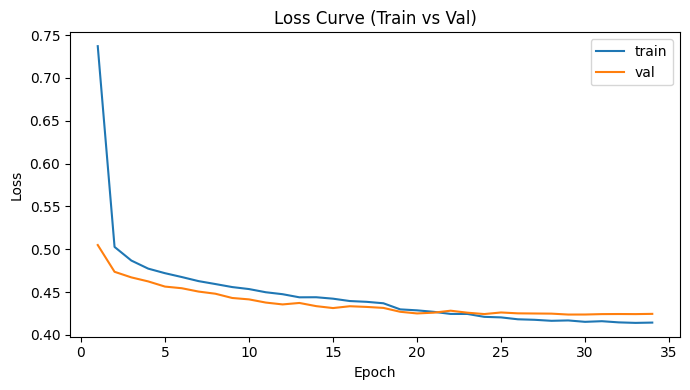

Saved: /kaggle/working/output/figures/phase3_unet_efficientnetb3_iou_curve.png | bytes: 150009


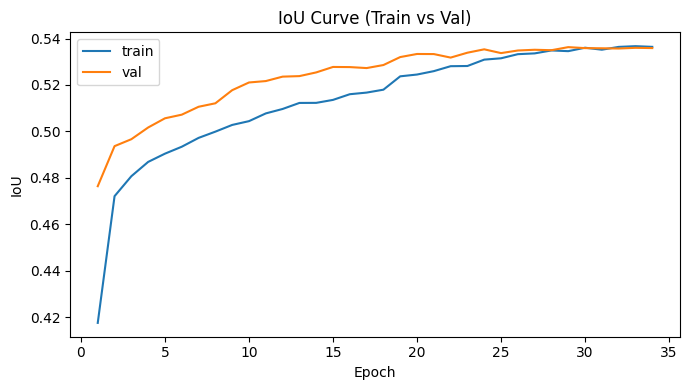

Saved: /kaggle/working/output/figures/phase3_unet_efficientnetb3_pixel_acc_curve.png | bytes: 157783


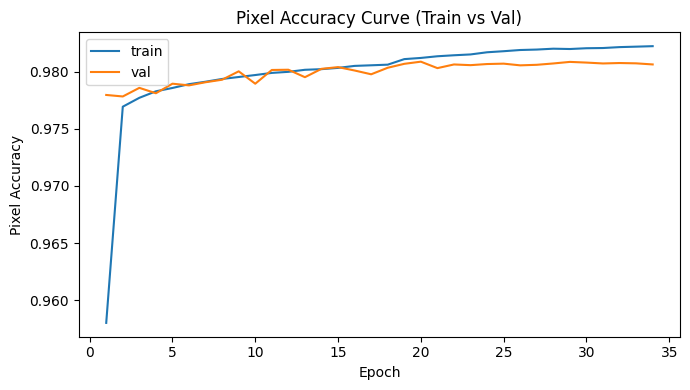

Curves saved in: /kaggle/working/output/figures


In [30]:
hist_df = pd.read_csv(RUN_DIR / f"{MODEL_NAME}_history.csv")

# Loss curve
fig1, ax1 = plt.subplots(figsize=(7,4))
ax1.plot(hist_df["epoch"], hist_df["train_loss"], label="train")
ax1.plot(hist_df["epoch"], hist_df["val_loss"], label="val")
ax1.set_title("Loss Curve (Train vs Val)")
ax1.set_xlabel("Epoch")
ax1.set_ylabel("Loss")
ax1.legend()
fig1.tight_layout()
fig_save(fig1, f"phase3_{MODEL_NAME}_loss_curve.png", dpi=450)
plt.show()
plt.close(fig1)

# IoU curve
fig2, ax2 = plt.subplots(figsize=(7,4))
ax2.plot(hist_df["epoch"], hist_df["train_iou"], label="train")
ax2.plot(hist_df["epoch"], hist_df["val_iou"], label="val")
ax2.set_title("IoU Curve (Train vs Val)")
ax2.set_xlabel("Epoch")
ax2.set_ylabel("IoU")
ax2.legend()
fig2.tight_layout()
fig_save(fig2, f"phase3_{MODEL_NAME}_iou_curve.png", dpi=450)
plt.show()
plt.close(fig2)

# Pixel accuracy curve
fig3, ax3 = plt.subplots(figsize=(7,4))
ax3.plot(hist_df["epoch"], hist_df["train_pixel_acc"], label="train")
ax3.plot(hist_df["epoch"], hist_df["val_pixel_acc"], label="val")
ax3.set_title("Pixel Accuracy Curve (Train vs Val)")
ax3.set_xlabel("Epoch")
ax3.set_ylabel("Pixel Accuracy")
ax3.legend()
fig3.tight_layout()
fig_save(fig3, f"phase3_{MODEL_NAME}_pixel_acc_curve.png", dpi=450)
plt.show()
plt.close(fig3)

print("Curves saved in:", FIG_DIR)


# Phase-3 Cell-11 — Load BEST checkpoint (for all evaluation)

In [31]:
import torch

MODEL_NAME = "unet_efficientnetb3"
BEST_CKPT = CKPT_DIR / f"{MODEL_NAME}_best.pt"

ckpt = torch.load(BEST_CKPT, map_location=DEVICE)
model.load_state_dict(ckpt["model_state"])
model.eval()

print("Loaded:", BEST_CKPT)
print("Best epoch:", ckpt.get("epoch"), "Best IoU:", ckpt.get("best_metric"))


Loaded: /kaggle/working/output/runs/seg_unet_v1/checkpoints/unet_efficientnetb3_best.pt
Best epoch: 29 Best IoU: 0.5363062802754658


# Phase-3 Cell-12 — Validation metrics per image + IoU histogram (saved)

Saved: /kaggle/working/output/runs/seg_unet_v1/unet_efficientnetb3_val_metrics.csv
               iou         dice     conf_max
count  1695.000000  1695.000000  1695.000000
mean      0.535594     0.654963     0.879335
std       0.240191     0.275533     0.319766
min       0.000000     0.000000     0.003635
25%       0.476715     0.645643     0.998047
50%       0.627758     0.771316     0.999512
75%       0.681631     0.810679     0.999512
max       0.899800     0.947257     1.000000
Saved: /kaggle/working/output/figures/phase3_unet_efficientnetb3_val_iou_hist.png | bytes: 81000


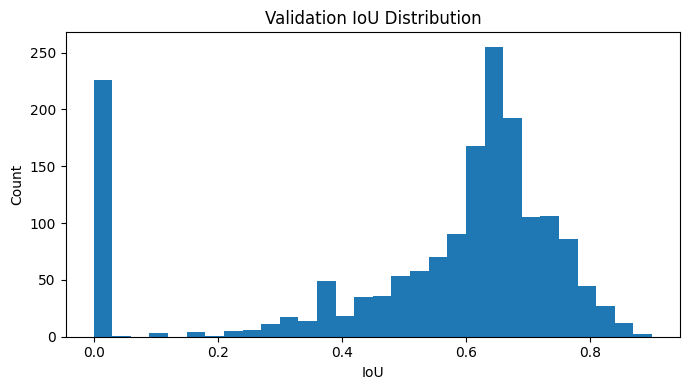

In [32]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import albumentations as A

VIS_SIZE = IMG_SIZE
vis_resize = A.Compose([A.Resize(VIS_SIZE, VIS_SIZE)])

def load_vis_image(img_path: str):
    img = np.array(Image.open(img_path).convert("RGB"))
    img = vis_resize(image=img, mask=np.zeros((img.shape[0], img.shape[1]), dtype=np.uint8))["image"]
    return img

def load_gt_mask(mask_path: str):
    m = np.array(Image.open(mask_path))
    if m.ndim == 3:
        m = m[..., 0]
    m = (m > 0).astype(np.uint8)
    m = vis_resize(image=np.zeros((m.shape[0], m.shape[1], 3), dtype=np.uint8), mask=m)["mask"]
    return m

def pred_prob_and_mask(img_path: str, thr=0.5):
    img = np.array(Image.open(img_path).convert("RGB"))
    out = val_tfms(image=img, mask=np.zeros((img.shape[0], img.shape[1]), dtype=np.uint8))
    x = out["image"].unsqueeze(0).to(DEVICE)

    with torch.no_grad():
        with autocast_ctx():
            logits = model(x)
        prob = torch.sigmoid(logits).squeeze().float().cpu().numpy()

    pred = (prob > thr).astype(np.uint8)
    return prob, pred

def iou_from_masks(pred, gt, eps=1e-6):
    inter = (pred * gt).sum()
    union = pred.sum() + gt.sum() - inter + eps
    return float(inter / union)

def dice_from_masks(pred, gt, eps=1e-6):
    inter = (pred * gt).sum()
    den = pred.sum() + gt.sum() + eps
    return float((2 * inter) / den)

rows = []
for i in range(len(val_df)):
    ip = val_df.loc[i, "image_path"]
    mp = val_df.loc[i, "mask_path"]
    gt = load_gt_mask(mp)
    prob, pred = pred_prob_and_mask(ip, thr=0.5)

    rows.append({
        "stem": val_df.loc[i, "stem"],
        "iou": iou_from_masks(pred, gt),
        "dice": dice_from_masks(pred, gt),
        "gt_has_crack": int(gt.sum() > 0),
        "pred_has_crack": int(pred.sum() > 0),
        "pred_crack_pixels": int(pred.sum()),
        "conf_max": float(prob.max()),
        "conf_mean": float(prob.mean())
    })

val_metrics = pd.DataFrame(rows)
val_metrics_path = RUN_DIR / f"{MODEL_NAME}_val_metrics.csv"
val_metrics.to_csv(val_metrics_path, index=False)
print("Saved:", val_metrics_path)

print(val_metrics[["iou","dice","conf_max"]].describe())

fig, ax = plt.subplots(figsize=(7,4))
ax.hist(val_metrics["iou"], bins=30)
ax.set_title("Validation IoU Distribution")
ax.set_xlabel("IoU")
ax.set_ylabel("Count")
fig.tight_layout()
fig_save(fig, f"phase3_{MODEL_NAME}_val_iou_hist.png", dpi=450)
plt.show()
plt.close(fig)


# Phase-3 Cell-13 — Top-K worst cases gallery

Saved: /kaggle/working/output/figures/phase3_unet_efficientnetb3_topk_worst_gallery.png | bytes: 15383881


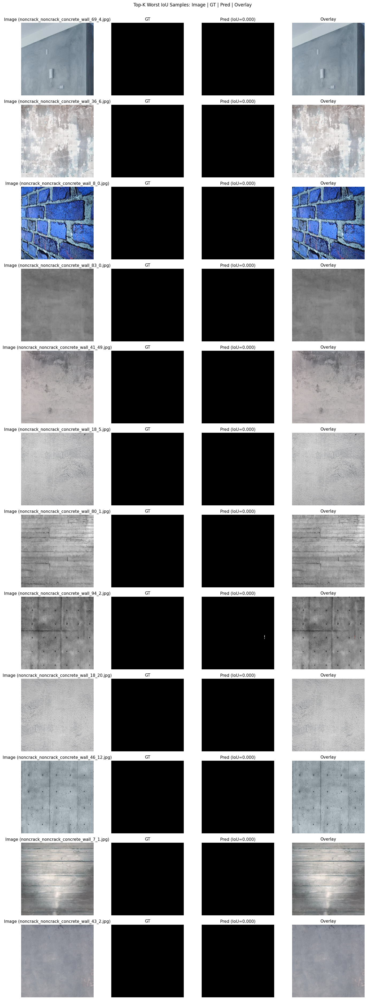

In [33]:
import matplotlib.pyplot as plt
import numpy as np

k = 12
worst = val_metrics.sort_values("iou", ascending=True).head(k).reset_index(drop=True)

fig, axes = plt.subplots(k, 4, figsize=(14, 3.1*k))
fig.suptitle("Top-K Worst IoU Samples: Image | GT | Pred | Overlay", y=1.002)

for r in range(k):
    stem = worst.loc[r, "stem"]
    row = val_df[val_df["stem"] == stem].iloc[0]
    ip, mp = row["image_path"], row["mask_path"]

    img = load_vis_image(ip)
    gt  = load_gt_mask(mp)
    prob, pred = pred_prob_and_mask(ip, thr=0.5)

    overlay = img.copy()
    overlay[pred == 1] = (0.7*overlay[pred == 1] + 0.3*np.array([255, 0, 0])).astype(np.uint8)

    axes[r,0].imshow(img); axes[r,0].axis("off"); axes[r,0].set_title(f"Image ({stem})", fontsize=11)
    axes[r,1].imshow(gt, cmap="gray"); axes[r,1].axis("off"); axes[r,1].set_title("GT", fontsize=11)
    axes[r,2].imshow(pred, cmap="gray"); axes[r,2].axis("off"); axes[r,2].set_title(f"Pred (IoU={worst.loc[r,'iou']:.3f})", fontsize=11)
    axes[r,3].imshow(overlay); axes[r,3].axis("off"); axes[r,3].set_title("Overlay", fontsize=11)

fig.tight_layout()
fig_save(fig, f"phase3_{MODEL_NAME}_topk_worst_gallery.png", dpi=450)
plt.show()
plt.close(fig)


# Phase-3 Cell-14 — Pixel-level Precision–Recall curve (sampled pixels) + save

Saved: /kaggle/working/output/figures/phase3_unet_efficientnetb3_pixel_pr_curve.png | bytes: 129509


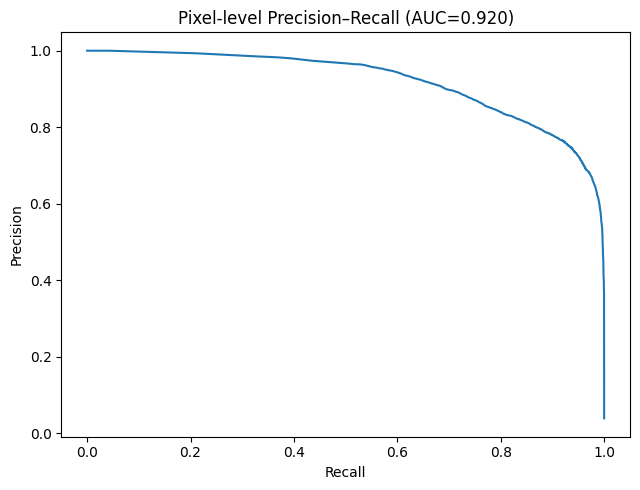

Sampled pixels: 300000  | PR AUC: 0.920284617817323


In [34]:
!pip -q install scikit-learn

from sklearn.metrics import precision_recall_curve, auc
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(7)
max_pixels = 300_000

probs_all = []
gts_all = []
collected = 0

for i in range(len(val_df)):
    ip = val_df.loc[i, "image_path"]
    mp = val_df.loc[i, "mask_path"]

    gt = load_gt_mask(mp).astype(np.uint8).reshape(-1)
    prob, _ = pred_prob_and_mask(ip, thr=0.5)
    prob = prob.reshape(-1)

    n = gt.size
    take = min(n, max_pixels - collected)
    if take <= 0:
        break

    idx = rng.choice(n, size=take, replace=False)
    probs_all.append(prob[idx])
    gts_all.append(gt[idx])
    collected += take

probs_all = np.concatenate(probs_all)
gts_all = np.concatenate(gts_all)

prec, rec, thr = precision_recall_curve(gts_all, probs_all)
pr_auc = auc(rec, prec)

fig, ax = plt.subplots(figsize=(6.5,5))
ax.plot(rec, prec)
ax.set_title(f"Pixel-level Precision–Recall (AUC={pr_auc:.3f})")
ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
fig.tight_layout()
fig_save(fig, f"phase3_{MODEL_NAME}_pixel_pr_curve.png", dpi=450)
plt.show()
plt.close(fig)

print("Sampled pixels:", collected, " | PR AUC:", pr_auc)


# Phase-3 Cell-15 — Object detection style: Mask → Bounding Boxes + overlays + save

Saved: /kaggle/working/output/figures/phase3_unet_efficientnetb3_bbox_overlays.png | bytes: 14757242


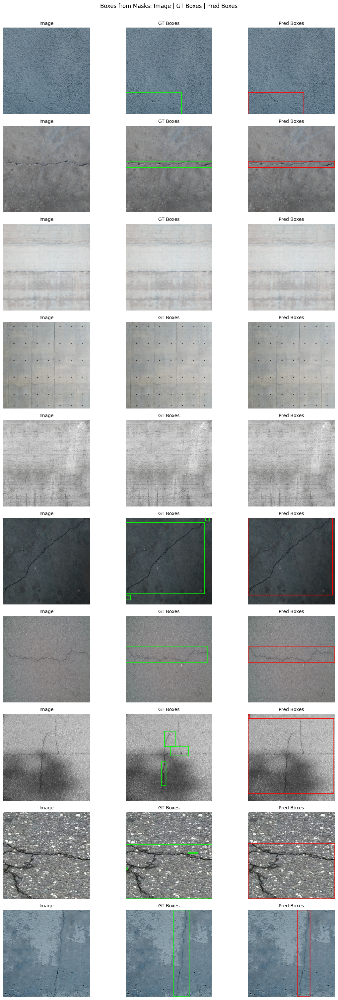

In [35]:
!pip -q install opencv-python-headless

import cv2
import numpy as np
import matplotlib.pyplot as plt
import random

def mask_to_boxes(mask01):
    m = (mask01.astype(np.uint8) * 255)
    n, labels, stats, _ = cv2.connectedComponentsWithStats(m, connectivity=8)
    boxes = []
    for k in range(1, n):
        x, y, w, h, area = stats[k]
        if area < 30:
            continue
        boxes.append((x, y, x+w, y+h, int(area)))
    boxes = sorted(boxes, key=lambda t: t[4], reverse=True)
    return boxes

def draw_boxes(img, boxes, color):
    out = img.copy()
    for (x1,y1,x2,y2,_) in boxes[:3]:
        cv2.rectangle(out, (x1,y1), (x2,y2), color, 2)
    return out

n_show = 10
sample_idx = random.sample(range(len(val_df)), k=min(n_show, len(val_df)))

fig, axes = plt.subplots(len(sample_idx), 3, figsize=(12, 3.0*len(sample_idx)))
fig.suptitle("Boxes from Masks: Image | GT Boxes | Pred Boxes", y=1.002)

for r, idx in enumerate(sample_idx):
    ip = val_df.loc[idx, "image_path"]
    mp = val_df.loc[idx, "mask_path"]

    img = load_vis_image(ip)
    gt  = load_gt_mask(mp)
    _, pred = pred_prob_and_mask(ip, thr=0.5)

    gt_boxes   = mask_to_boxes(gt)
    pred_boxes = mask_to_boxes(pred)

    img_gt   = draw_boxes(img, gt_boxes, (0,255,0))
    img_pred = draw_boxes(img, pred_boxes, (255,0,0))

    axes[r,0].imshow(img);      axes[r,0].axis("off"); axes[r,0].set_title("Image", fontsize=10)
    axes[r,1].imshow(img_gt);   axes[r,1].axis("off"); axes[r,1].set_title("GT Boxes", fontsize=10)
    axes[r,2].imshow(img_pred); axes[r,2].axis("off"); axes[r,2].set_title("Pred Boxes", fontsize=10)

fig.tight_layout()
fig_save(fig, f"phase3_{MODEL_NAME}_bbox_overlays.png", dpi=450)
plt.show()
plt.close(fig)


# Phase-3 Cell-17 — Fix reporting (crack-only IoU + no-crack false positive rate)

In [36]:
import pandas as pd
import numpy as np

# val_metrics must exist from your earlier cell
assert "val_metrics" in globals(), "Run the val_metrics creation cell first."

df = val_metrics.copy()

crack = df[df["gt_has_crack"] == 1].copy()
noc   = df[df["gt_has_crack"] == 0].copy()

# "Empty-aware IoU": if GT has no crack and model predicts no crack => score 1.0
# Otherwise keep normal IoU (this is common to avoid punishing correct empty predictions).
df["iou_emptyaware"] = df["iou"].values
df.loc[(df.gt_has_crack==0) & (df.pred_has_crack==0), "iou_emptyaware"] = 1.0
df.loc[(df.gt_has_crack==0) & (df.pred_has_crack==1), "iou_emptyaware"] = 0.0

summary = {
    "n_val": len(df),
    "n_gt_crack": len(crack),
    "n_gt_nocrack": len(noc),
    "mean_iou_all": float(df["iou"].mean()),
    "mean_iou_crack_only": float(crack["iou"].mean()),
    "median_iou_crack_only": float(crack["iou"].median()),
    "mean_dice_crack_only": float(crack["dice"].mean()),
    "no_crack_false_positive_rate": float((noc["pred_has_crack"] == 1).mean()),
    "no_crack_false_positive_count": int((noc["pred_has_crack"] == 1).sum()),
    "no_crack_true_negative_count": int((noc["pred_has_crack"] == 0).sum()),
    "mean_iou_emptyaware_all": float(df["iou_emptyaware"].mean())
}

summary_df = pd.DataFrame([summary])
print(summary_df.T)

save_path = RUN_DIR / f"{MODEL_NAME}_val_summary_report.csv"
summary_df.to_csv(save_path, index=False)
print("Saved:", save_path)


                                         0
n_val                          1695.000000
n_gt_crack                     1477.000000
n_gt_nocrack                    218.000000
mean_iou_all                      0.535594
mean_iou_crack_only               0.614646
median_iou_crack_only             0.640517
mean_dice_crack_only              0.751633
no_crack_false_positive_rate      0.059633
no_crack_false_positive_count    13.000000
no_crack_true_negative_count    205.000000
mean_iou_emptyaware_all           0.656538
Saved: /kaggle/working/output/runs/seg_unet_v1/unet_efficientnetb3_val_summary_report.csv


# Phase-3 Cell-18 — Update IoU histogram to avoid misleading “0 spike”

Saved: /kaggle/working/output/figures/phase3_unet_efficientnetb3_val_iou_hist_crack_only.png | bytes: 97414


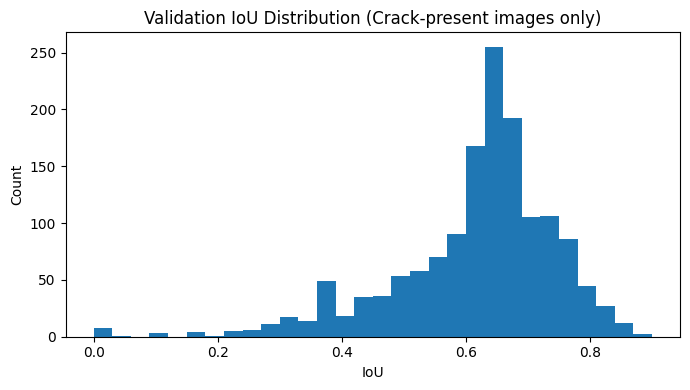

In [37]:
import matplotlib.pyplot as plt

df = val_metrics.copy()
crack = df[df["gt_has_crack"] == 1].copy()

fig, ax = plt.subplots(figsize=(7,4))
ax.hist(crack["iou"], bins=30)
ax.set_title("Validation IoU Distribution (Crack-present images only)")
ax.set_xlabel("IoU")
ax.set_ylabel("Count")
fig.tight_layout()
fig_save(fig, f"phase3_{MODEL_NAME}_val_iou_hist_crack_only.png", dpi=450)
plt.show()
plt.close(fig)


# Phase-3 Cell-19 — Fix Top-K “worst cases” gallery (only crack-present)

Saved: /kaggle/working/output/figures/phase3_unet_efficientnetb3_topk_worst_gallery_crack_only.png | bytes: 21400377


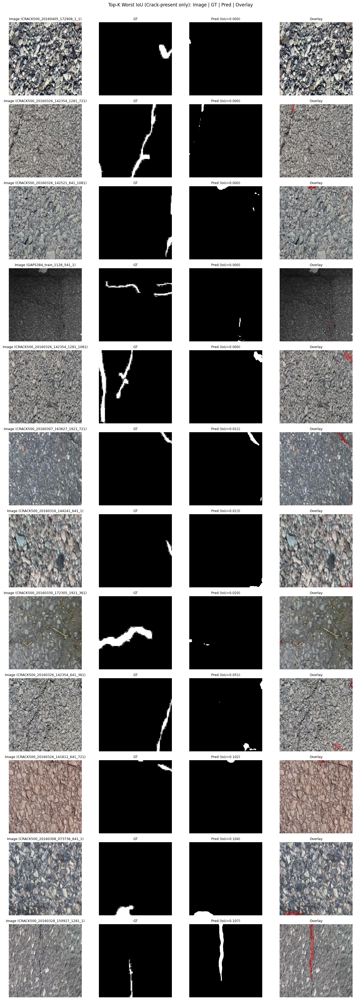

In [38]:
import matplotlib.pyplot as plt
import numpy as np

df = val_metrics.copy()
df = df[df["gt_has_crack"] == 1].copy()

k = 12
worst = df.sort_values("iou", ascending=True).head(k).reset_index(drop=True)

fig, axes = plt.subplots(k, 4, figsize=(14, 3.1*k))
fig.suptitle("Top-K Worst IoU (Crack-present only): Image | GT | Pred | Overlay", y=1.002)

for r in range(k):
    stem = worst.loc[r, "stem"]
    row = val_df[val_df["stem"] == stem].iloc[0]
    ip, mp = row["image_path"], row["mask_path"]

    img = load_vis_image(ip)
    gt  = load_gt_mask(mp)
    prob, pred = pred_prob_and_mask(ip, thr=0.5)

    overlay = img.copy()
    overlay[pred == 1] = (0.7*overlay[pred == 1] + 0.3*np.array([255, 0, 0])).astype(np.uint8)

    axes[r,0].imshow(img); axes[r,0].axis("off"); axes[r,0].set_title(f"Image ({stem})", fontsize=9)
    axes[r,1].imshow(gt, cmap="gray"); axes[r,1].axis("off"); axes[r,1].set_title("GT", fontsize=9)
    axes[r,2].imshow(pred, cmap="gray"); axes[r,2].axis("off"); axes[r,2].set_title(f"Pred (IoU={worst.loc[r,'iou']:.3f})", fontsize=9)
    axes[r,3].imshow(overlay); axes[r,3].axis("off"); axes[r,3].set_title("Overlay", fontsize=9)

fig.tight_layout()
fig_save(fig, f"phase3_{MODEL_NAME}_topk_worst_gallery_crack_only.png", dpi=450)
plt.show()
plt.close(fig)


In [39]:
# === SAVE + RENAME + ZIP: find all .pt/.pth under /kaggle/working and collect them neatly ===

from pathlib import Path
import shutil, zipfile, datetime
import torch

WORK = Path("/kaggle/working")

# Where to put the final, easy-to-find model files
DEST_DIR = WORK / "output" / "SAVED_MODELS"
DEST_DIR.mkdir(parents=True, exist_ok=True)

# Find all checkpoint-like files in the workspace (ignore /kaggle/input)
found = []
for pat in ("*.pt", "*.pth", "*.bin"):
    found += [p for p in WORK.rglob(pat) if "/kaggle/input" not in str(p)]

found = sorted(set(found))

print(f"Found {len(found)} model files under {WORK}:")
for p in found[:50]:
    print(" -", p, "|", round(p.stat().st_size/1024/1024, 2), "MB")
if len(found) > 50:
    print(" ... (showing first 50)")

def safe_float(x):
    try:
        return float(x)
    except:
        return None

def make_nice_name(path: Path):
    """
    Tries to read epoch/best_iou from checkpoint dict to create a convenient filename.
    Falls back safely if it can't read.
    """
    stamp = datetime.datetime.now().strftime("%Y%m%d_%H%M%S")
    epoch = None
    best_iou = None
    model_name = None

    try:
        ckpt = torch.load(path, map_location="cpu")
        if isinstance(ckpt, dict):
            epoch = ckpt.get("epoch", None)
            best_iou = ckpt.get("best_iou", ckpt.get("best_score", None))
            model_name = ckpt.get("model_name", ckpt.get("MODEL_NAME", None))
    except Exception:
        pass

    parts = []
    parts.append(str(model_name) if model_name else path.stem)
    if epoch is not None:
        try:
            parts.append(f"ep{int(epoch):03d}")
        except:
            parts.append(f"ep{epoch}")
    bi = safe_float(best_iou)
    if bi is not None:
        parts.append(f"bestIoU{bi:.4f}")
    parts.append(stamp)
    return "_".join(parts) + path.suffix

# Copy + rename
copied = []
for src in found:
    new_name = make_nice_name(src)
    dst = DEST_DIR / new_name

    # avoid overwriting if same name happens
    if dst.exists():
        dst = DEST_DIR / (dst.stem + "_dup" + dst.suffix)

    shutil.copy2(src, dst)
    copied.append(dst)

print("\nCopied files into:", DEST_DIR)
for p in copied:
    print(" -", p.name, "|", round(p.stat().st_size/1024/1024, 2), "MB")

# Make a ZIP for easy download
zip_path = WORK / "output" / "SAVED_MODELS.zip"
with zipfile.ZipFile(zip_path, "w", compression=zipfile.ZIP_DEFLATED) as z:
    for p in copied:
        z.write(p, arcname=str(p.relative_to(WORK)))

print("\nZIP created:", zip_path, "|", round(zip_path.stat().st_size/1024/1024, 2), "MB")

# Quick tree view (helps confirm where checkpoints were originally saved)
print("\nIf you expected checkpoints in a specific folder, check these common paths:")
common = [
    WORK / "output" / "runs",
    WORK / "output" / "runs" / "seg_unet_v1",
    WORK / "output" / "runs" / "seg_unet_v1" / "checkpoints",
]
for c in common:
    print(" -", c, "| exists:", c.exists())
    if c.exists():
        pts = list(c.glob("*.pt")) + list(c.glob("*.pth"))
        print("    contains:", len(pts), "pt/pth files")


Found 2 model files under /kaggle/working:
 - /kaggle/working/output/runs/seg_unet_v1/checkpoints/unet_efficientnetb3_best.pt | 146.95 MB
 - /kaggle/working/output/runs/seg_unet_v1/checkpoints/unet_efficientnetb3_last.pt | 146.95 MB

Copied files into: /kaggle/working/output/SAVED_MODELS
 - unet_efficientnetb3_best_ep029_20260220_015743.pt | 146.95 MB
 - unet_efficientnetb3_last_ep034_20260220_015743.pt | 146.95 MB

ZIP created: /kaggle/working/output/SAVED_MODELS.zip | 271.43 MB

If you expected checkpoints in a specific folder, check these common paths:
 - /kaggle/working/output/runs | exists: True
    contains: 0 pt/pth files
 - /kaggle/working/output/runs/seg_unet_v1 | exists: True
    contains: 0 pt/pth files
 - /kaggle/working/output/runs/seg_unet_v1/checkpoints | exists: True
    contains: 2 pt/pth files
